1. take k= {3,5,7,9,11}. For each value of k compute the accuracy of your k-NN classifier on training years data. On the x-axis you plot kand on the y-axis you plot accuracy. What is the optimal value of k for training years?

(156, 2)
k = 3, accuracy = 75.0%
k = 5, accuracy = 75.0%
k = 7, accuracy = 73.08%
k = 9, accuracy = 69.23%
k = 11, accuracy = 63.46%


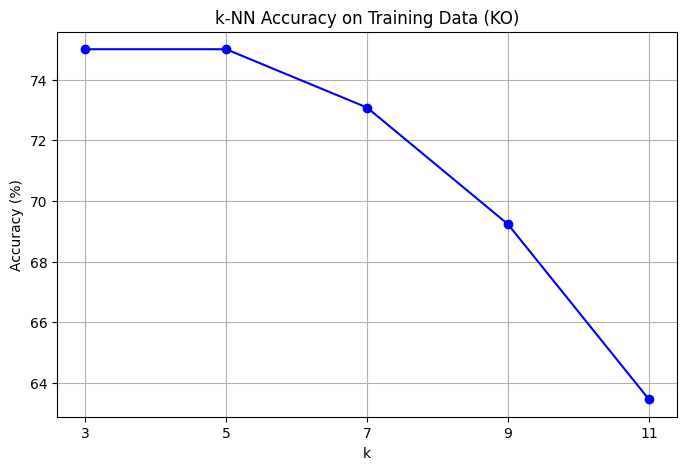

In [7]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

df = pd.read_csv('KO_weekly_return_volatility.csv')

train = df[df['Year'].isin([2021, 2022, 2023])]
test = df[df['Year'].isin([2024, 2025])]

X_train = train[['mean_return', 'volatility']].values
Y_train = train['decision'].values
X_test = test[['mean_return', 'volatility']].values
Y_test = test['decision'].values

print(X_train.shape)

k_values = [3, 5, 7, 9, 11]
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, Y_train)
    accuracy = knn.score(X_train, Y_train)
    accuracies.append(accuracy)
    print(f'k = {k}, accuracy = {round(accuracy * 100, 2)}%')

# plotting how accuracy changes with different k values
plt.figure(figsize=(8, 5))
plt.plot(k_values, [a * 100 for a in accuracies], marker='o', color='blue')
plt.xlabel('k')
plt.ylabel('Accuracy (%)')
plt.title('k-NN Accuracy on Training Data (KO)')
plt.xticks(k_values)
plt.grid(True)
plt.savefig('knn_accuracy_plot.png')
plt.show()


2. use the optimal value of k from training years to predict labels for testing years. What is your accuracy?

In [2]:
# using our best k=5 to predict testing years
best_k = 5
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, Y_train)

# predicting on test data now
test_accuracy = knn.score(X_test, Y_test)
print(f'Test accuracy with k={best_k}: {round(test_accuracy * 100, 2)}%')

Test accuracy with k=5: 60.38%


3. usingtheoptimalvalueforkfromtrainingyears, compute the confusion matrix for testing years

In [3]:
from sklearn.metrics import confusion_matrix

# getting predictions for test data
predictions = knn.predict(X_test)

# confusion matrix
cm = confusion_matrix(Y_test, predictions, labels=['YES', 'NO'])
print('Confusion Matrix:')
print(f'                Predicted YES   Predicted NO')
print(f'Actual YES      {cm[0][0]}              {cm[0][1]}')
print(f'Actual NO       {cm[1][0]}              {cm[1][1]}')

Confusion Matrix:
                Predicted YES   Predicted NO
Actual YES      7              26
Actual NO       16              57


4. what is true positive rate (sensitivity or recall) and true negative rate (specificity) for testing years?

In [4]:
TP = cm[0][0]  # 7
FN = cm[0][1]  # 26
FP = cm[1][0]  # 16
TN = cm[1][1]  # 57

TPR = TP / (TP + FN)
TNR = TN / (TN + FP)

print(f'TPR (sensitivity): {round(TPR * 100, 2)}%')
print(f'TNR (specificity): {round(TNR * 100, 2)}%')

TPR (sensitivity): 21.21%
TNR (specificity): 78.08%


5. implement a trading strategy based on your labels for testing years and compare the performance with the"buy-and-hold"strategy for the same time-period. Which strategy results in a larger amount at the end of the year?

In [6]:
# we need daily data for test years to apply returns day by day
daily_data = pd.read_csv('KO_weekly_return_detailed.csv')
daily_test = daily_data[daily_data['Year'].isin([2024, 2025])].reset_index(drop=True)

# putting our knn predictions into the test dataframe so we can use them
test_reset = test.reset_index(drop=True)
test_reset['knn_prediction'] = predictions

#  KNN TRADING
initial_balance = 100
knn_balance = initial_balance
position = None

for week_idx in range(len(test_reset)):
    current_week = test_reset.iloc[week_idx]
    year = current_week['Year']
    week_num = current_week['Week_Number']

    week_data = daily_test[
        (daily_test['Year'] == year) &
        (daily_test['Week_Number'] == week_num)
    ]

    if len(week_data) == 0:
        continue

    # if we're invested, apply daily returns
    if position == 'invested':
        for idx, row in week_data.iterrows():
            if pd.notna(row['Return']):
                knn_balance = knn_balance * (1 + row['Return'] / 100)

    # check next week's prediction to decide what to do
    if week_idx < len(test_reset) - 1:
        next_prediction = test_reset.iloc[week_idx + 1]['knn_prediction']
        if next_prediction == 'YES':
            position = 'invested'
        else:
            position = None

# BUY AND HOLD
bh_balance = initial_balance

for idx, row in daily_test.iterrows():
    if pd.notna(row['Return']):
        bh_balance = bh_balance * (1 + row['Return'] / 100)

print(f'KNN Strategy Final Balance: ${knn_balance:.2f}')
print(f'Buy and Hold Final Balance: ${bh_balance:.2f}')

KNN Strategy Final Balance: $106.40
Buy and Hold Final Balance: $126.14


Buy and Hold strategy results in a larger amount at the end of the testing period